# Assignment 2: Module 1, Fuzzy Logic

---

## Practical 10: Fuzzy Logic Controller

### Aim
To design a fuzzy logic controller with scikit-fuzzy by combining membership functions, fuzzy rules, inference and defuzzification.

### Theory
A fuzzy logic controller has four parts:
1. **Fuzzification**: crisp inputs are converted into membership values.
2. **Rule base**: IF-THEN rules describe the control action.
3. **Inference**: the rules are evaluated and their outputs combined.
4. **Defuzzification**: the combined fuzzy output is converted into a crisp control value.

This controller sets the fan speed of a room cooler from the temperature and the humidity. It uses 3 terms for each input and a full 3 x 3 rule grid, so it has 9 rules.

### Implementation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# 1. Inputs and output
temperature = ctrl.Antecedent(np.arange(0, 41, 1), "temperature")
humidity = ctrl.Antecedent(np.arange(0, 101, 1), "humidity")
fan_speed = ctrl.Consequent(np.arange(0, 101, 1), "fan_speed", defuzzify_method="centroid")


In [2]:
# 2. Membership functions
temperature["low"] = fuzz.trimf(temperature.universe, [0, 0, 20])
temperature["medium"] = fuzz.trimf(temperature.universe, [10, 20, 30])
temperature["high"] = fuzz.trimf(temperature.universe, [20, 40, 40])

humidity["low"] = fuzz.trimf(humidity.universe, [0, 0, 50])
humidity["medium"] = fuzz.trimf(humidity.universe, [25, 50, 75])
humidity["high"] = fuzz.trimf(humidity.universe, [50, 100, 100])

fan_speed["slow"] = fuzz.trimf(fan_speed.universe, [0, 0, 50])
fan_speed["medium"] = fuzz.trimf(fan_speed.universe, [25, 50, 75])
fan_speed["fast"] = fuzz.trimf(fan_speed.universe, [50, 100, 100])


In [3]:
# 3. Rule base (3 x 3 grid)
rule_table = {
    ("low", "low"): "slow",       ("low", "medium"): "slow",      ("low", "high"): "medium",
    ("medium", "low"): "slow",    ("medium", "medium"): "medium", ("medium", "high"): "fast",
    ("high", "low"): "medium",    ("high", "medium"): "fast",     ("high", "high"): "fast",
}

rules = [
    ctrl.Rule(temperature[t] & humidity[h], fan_speed[out])
    for (t, h), out in rule_table.items()
]

# 4. Build the controller
fan_ctrl = ctrl.ControlSystem(rules)
fan = ctrl.ControlSystemSimulation(fan_ctrl)


In [4]:
# 5. Test some scenarios
print(f"{'Temp (C)':>9}{'Humidity (%)':>14}{'Fan speed (%)':>15}")
for t_val, h_val in [(5, 20), (25, 60), (38, 90), (15, 80)]:
    fan.input["temperature"] = t_val
    fan.input["humidity"] = h_val
    fan.compute()
    print(f"{t_val:>9}{h_val:>14}{fan.output['fan_speed']:>15.2f}")


 Temp (C)  Humidity (%)  Fan speed (%)
        5            20          18.57
       25            60          59.79
       38            90          82.78
       15            80          70.14


### Visualization


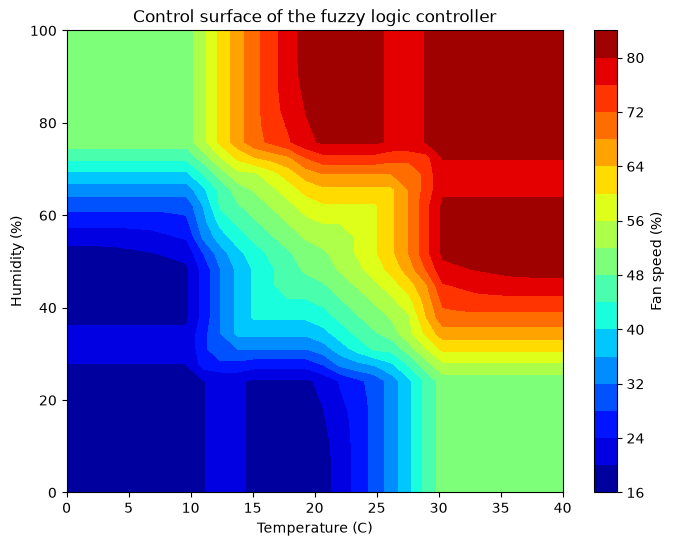

In [5]:
# 6. Control surface: fan speed for every combination of temperature and humidity
T_grid = np.linspace(0, 40, 30)
H_grid = np.linspace(0, 100, 30)
Z = np.zeros((len(H_grid), len(T_grid)))

for i, h_val in enumerate(H_grid):
    for j, t_val in enumerate(T_grid):
        fan.input["temperature"] = t_val
        fan.input["humidity"] = h_val
        fan.compute()
        Z[i, j] = fan.output["fan_speed"]

plt.figure(figsize=(8, 6))
cs = plt.contourf(T_grid, H_grid, Z, levels=20, cmap="jet")
plt.colorbar(cs, label="Fan speed (%)")
plt.xlabel("Temperature (C)")
plt.ylabel("Humidity (%)")
plt.title("Control surface of the fuzzy logic controller")
plt.show()


e:\shivam projects\Assignement 1\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


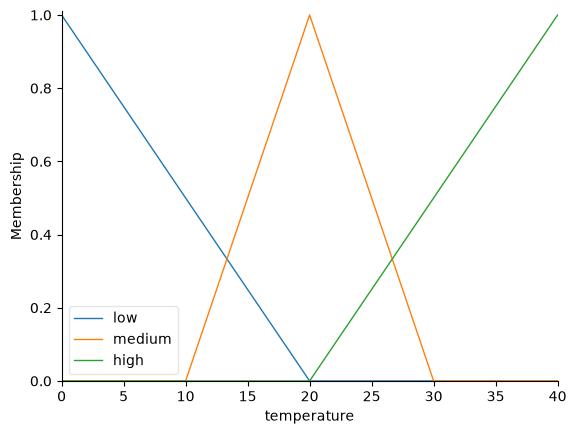

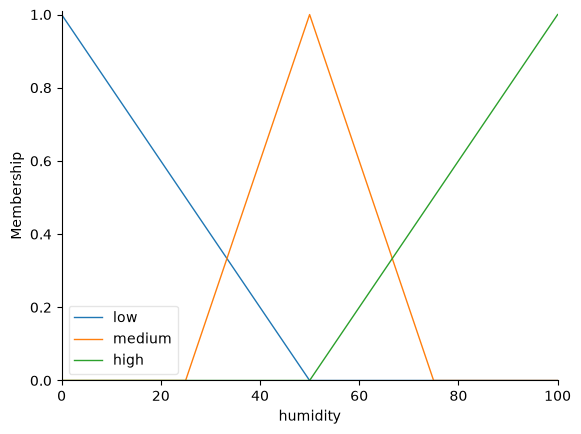

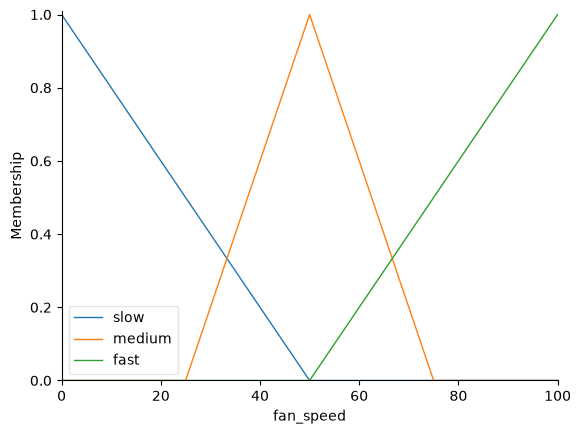

In [6]:
# 7. Membership functions used by the controller
temperature.view()
humidity.view()
fan_speed.view()
plt.show()


### Observation
- At 5 C and 20 % humidity the fan runs at 18.57 %, which is slow.
- At 25 C and 60 % humidity the fan runs at 59.79 %, which is medium.
- At 38 C and 90 % humidity the fan runs at 82.78 %, which is fast.
- The control surface rises smoothly with both temperature and humidity, so the fan speed changes gradually instead of jumping.

### Conclusion
A complete fuzzy logic controller was designed with membership functions, a 9-rule base, Mamdani inference and centroid defuzzification. Its control surface was plotted to show how the controller behaves over the whole input range.
